# 📊 Trabajo Práctico - Análisis Exploratorio de Datos (EDA)
## Materia: Desarrollo de Sistemas de IA
### Integrantes del grupo:
- Fernanda Perez 1 - Dataset: Buenos Aires Real Estate
- Nancy Riquelme 2 - Dataset: Proyecto de Construcción
- Mercedes Sosa 3 - Dataset: construcción_en_seco
- Nahuel Linares 4 - Dataset: contrucción obra

---

## 🔍 Introducción
Cada integrante del grupo trabajó con un conjunto de datos distinto, cumpliendo con los requisitos mínimos: formato .csv o .xlsx, al menos 9 columnas y 2500 filas. En este notebook se integran todos los análisis exploratorios individuales, seguidos por una **conclusión grupal** que justifica la elección del dataset con el que se continuará el desarrollo del proyecto.

# DATABASE ELEGIDO:
## 📁 Dataset 1 – Buenos Aires Real Estate (Integrante: Fernanda Perez)

1. Carga y exploración de datos

In [1]:
#Librerias a utilizar
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.cluster import KMeans

# 1. Definimos el file_id y la URL de descarga directa
file_id = '1eNFGYL2YttBPRyZjjkJJEBm8y-N3Fg7U'
url = f'https://drive.google.com/uc?id={file_id}'

# 2. Intentamos cargar el dataset directamente desde la URL
try:
  # Separamos por ; ya que este archivo utiliza punto y coma
  inmuebles = pd.read_csv(url, sep=';')
  print(f'¡Archivo cargado exitosamente desde la URL!')
  print('Tamaño (filas, columnas):', inmuebles.shape)
except Exception as e:
  print(f'No se pudo cargar el archivo desde la URL. Error: {e}')
  # Inicializamos con las columnas mínimas esperadas para que no rompa el código posterior
  columnas_esperadas = [
      'property_type', 'price_aprox_usd', 'surface_total_in_m2', 'rooms',
      'place_with_parent_names', 'price', 'currency',
      'price_aprox_local_currency', 'expenses', 'price_usd_per_m2', 'price_per_m2'
  ]
  inmuebles = pd.DataFrame(columns=columnas_esperadas)

# Creamos las variables para el resto del equipo evitando recargas innecesarias
bs_as = inmuebles.copy()
df_ml = inmuebles.copy()

¡Archivo cargado exitosamente desde la URL!
Tamaño (filas, columnas): (8606, 16)


In [2]:
# CELDA DE DIAGNÓSTICO: Buscar todos los archivos CSV en tu Drive
import os
from google.colab import drive

try:
    # Intentar montar Drive por si acaso
    drive.mount('/content/drive')
    print("\n--- Buscando archivos .csv en tu Google Drive ---")
    encontrados = 0
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        for file in files:
            if file.endswith('.csv'):
                print(f"Archivo encontrado: {file} | Ruta: {os.path.join(root, file)}")
                encontrados += 1
    if encontrados == 0:
        print("No se encontró ningún archivo con extensión .csv en tu Google Drive. Por favor, sube el archivo a tu unidad.")
except Exception as e:
    print("Error al acceder a Google Drive:", e)

Mounted at /content/drive

--- Buscando archivos .csv en tu Google Drive ---
Archivo encontrado: buenos-aires-real-estate-1.csv | Ruta: /content/drive/MyDrive/buenos-aires-real-estate-1.csv


# Traducción:
operation: operación

property_type: tipo de propiedad

place_with_parent_names: ubicación completa

lat-lon: latitud y longitud

price: precio

currency: moneda

price_aprox_local_currency: precio aproximado en moneda local

price_aprox_usd: precio aproximado en dólares

surface_total_in_m2: superficie total en metros cuadrados

surface_covered_in_m2: superficie cubierta en metros cuadrados

price_usd_per_m2: precio en dólares por metro cuadrado

price_per_m2: precio por metro cuadrado

floor: piso

rooms: cantidad de ambientes

expenses: expensas

properati_url: enlace del aviso de la propiedad

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500,1.636.363.636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2.136.752.137,2.083.333.333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000,1.863.636.364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900,1.333.333.333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1.697.368.421,1.842.857.143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
8601,sell,apartment,|Argentina|Capital Federal|San Nicolás|,"-34.601455,-58.378132",125000.0,USD,1895300.0,125000.0,NaN,70.0,NaN,1.785.714.286,2.0,3.0,NaN,http://san-nicolas.properati.com.ar/1004t_vent...
8602,sell,house,|Argentina|Bs.As. G.B.A. Zona Norte|San Fernando|,NaN,480000.0,USD,7277952.0,480000.0,683.0,235.0,7.027.818.448,2.042.553.191,NaN,NaN,NaN,http://san-fernando-bs-as-g-b-a-zona-norte.pro...
8603,sell,house,|Argentina|Bs.As. G.B.A. Zona Norte|Tigre|Nord...,NaN,510000.0,USD,7732824.0,510000.0,0.0,256.0,NaN,19.921.875,NaN,NaN,NaN,http://nordelta.properati.com.ar/zg3s_venta_ca...
8604,sell,apartment,|Argentina|Capital Federal|Boedo|,NaN,78000.0,USD,1182667.2,78000.0,52.0,52.0,1500,1500,NaN,NaN,NaN,http://boedo.properati.com.ar/eh9b_venta_depar...
8605,sell,PH,|Argentina|Bs.As. G.B.A. Zona Norte|Pilar|,"-34.4541346,-58.9028747",65000.0,USD,985556.0,65000.0,90.0,60.0,7.222.222.222,1.083.333.333,NaN,NaN,NaN,http://pilar-bs-as-g-b-a-zona-norte.properati....


,price,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,floor,rooms
count,7.590000e+03,7.590000e+03,7.590000e+03,5946.000000,7268.000000,1259.000000,4752.000000
mean,2.982076e+05,3.591849e+06,2.368919e+05,252.829129,140.324436,8.802224,3.066498
std,5.074586e+05,4.758038e+06,3.138051e+05,938.374862,764.092931,59.640309,1.386481
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,1.000000,1.000000
25%,9.500000e+04,1.364616e+06,9.000000e+04,48.000000,46.000000,2.000000,2.000000
50%,1.550000e+05,2.228873e+06,1.470000e+05,95.000000,76.500000,3.000000,3.000000
75%,3.000000e+05,4.018036e+06,2.650000e+05,250.000000,160.000000,6.000000,4.000000
max,1.111111e+07,1.212992e+08,8.000000e+06,62034.000000,62034.000000,1503.000000,20.000000


,count,mean,std,min,25%,50%,75%,max
price,7590.0,2.982076e+05,5.074586e+05,0.0,95000.0,155000.0,300000.0,11111111.0
price_aprox_local_currency,7590.0,3.591849e+06,4.758038e+06,0.0,1364616.0,2228872.8,4018036.0,121299200.0
price_aprox_usd,7590.0,2.368919e+05,3.138051e+05,0.0,90000.0,147000.0,265000.0,8000000.0
surface_total_in_m2,5946.0,2.528291e+02,9.383749e+02,0.0,48.0,95.0,250.0,62034.0
surface_covered_in_m2,7268.0,1.403244e+02,7.640929e+02,0.0,46.0,76.5,160.0,62034.0
floor,1259.0,8.802224e+00,5.964031e+01,1.0,2.0,3.0,6.0,1503.0
rooms,4752.0,3.066498e+00,1.386481e+00,1.0,2.0,3.0,4.0,20.0


 
 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8606 entries, 0 to 8605
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   8606 non-null   object 
 1   property_type               8606 non-null   object 
 2   place_with_parent_names     8606 non-null   object 
 3   lat-lon                     6936 non-null   object 
 4   price                       7590 non-null   float64
 5   currency                    7590 non-null   object 
 6   price_aprox_local_currency  7590 non-null   float64
 7   price_aprox_usd             7590 non-null   float64
 8   surface_total_in_m2         5946 non-null   float64
 9   surface_covered_in_m2       7268 non-null   float64
 10  price_usd_per_m2            4895 non-null   object 
 11  price_per_m2                6520 non-null   object 
 12  floor                       1259 non-null   float64
 13  rooms                       4

<Axes: xlabel='surface_total_in_m2', ylabel='price'>

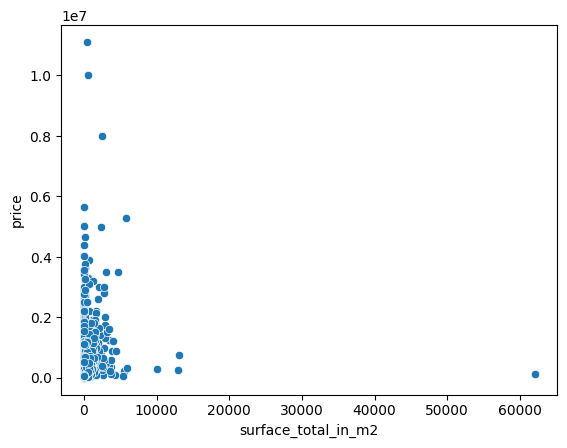

In [3]:
inmuebles.shape #indica las filas y columnas
print(" ")
print(" ")
inmuebles.dtypes #indica el tipo de datos de cada columna
print(" ")
print(" ")
display(inmuebles.head())# muestra las primeras 5 filas
print(" ")
print(" ")
display(inmuebles.tail())#muestra las ultimas 4 filas
print(" ")
print(" ")
display(inmuebles.describe())
print(" ")
print(" ")
display(inmuebles.describe().T)  # Muestra las estadísticas descriptivas de forma transpuesta
print(" ")
print(" ")
inmuebles.info()  # Muestra información general del DataFrame
print(" ")
print(" ")
print(inmuebles.isnull().sum())  # Muestra la cantidad de valores nulos de cada columna

sns.scatterplot(x="surface_total_in_m2", y="price", data=inmuebles)  # Relaciona la superficie total con el precio
# sns.pairplot(inmuebles)  # Compara entre sí las variables numéricas del dataset (Opcional, puede demorar)

###traducción
- operation: operación
- property_type: tipo de propiedad
- place_with_parent_names: ubicación completa
- lat-lon: latitud y longitud
- price: precio
- currency: moneda
- price_aprox_local_currency: precio aproximado en moneda local
- price_aprox_usd: precio aproximado en dólares
- surface_total_in_m2: superficie total en metros cuadrados
- surface_covered_in_m2: superficie cubierta en metros cuadrados
- price_usd_per_m2: precio en dólares por metro cuadrado
- price_per_m2: precio por metro cuadrado
- floor: piso
- rooms: cantidad de ambientes
- expenses: expensas
- properati_url: enlace del aviso de la propiedad

### 3. Observaciones generales
Breve resumen del análisis: ¿Qué patrones se observan? ¿Hay calidad en los datos? ¿Qué variables resultan más interesantes?


Después de analizar el dataset de inmuebles de Buenos Aires pude conocer mejor la información que contiene. Encontré datos sobre precios, tipos de propiedades, ubicación, superficie y cantidad de ambientes. También observé que hay valores faltantes en algunas columnas y algunos datos que llaman la atención, como superficies muy grandes o valores muy altos en la columna de piso.
Los gráficos me ayudaron a ver mejor la relación entre algunas variables, como la superficie y el precio. En general, me parece un dataset interesante para seguir trabajando, aunque sería necesario revisar y limpiar algunos datos antes de hacer otros análisis.



---



---

# LIMPIEZA Y VALIDACION DE DATOS:

In [4]:
faltantes = bs_as.isnull().sum()
print("Faltantes por columna:\n", faltantes)

# Calculamos el porcentaje solo si el DataFrame no está vacío para evitar NaN/divisiones por cero
if len(bs_as) > 0:
    porcentaje_faltantes = (bs_as.isnull().sum() / len(bs_as)) * 100
else:
    porcentaje_faltantes = bs_as.isnull().sum() * 0.0
print("\nPorcentaje de faltantes:\n", porcentaje_faltantes)

print("\nTamaño eliminando todos los nulos:", bs_as.dropna().shape)

columnas_precio = [col for col in ['price', 'currency', 'price_aprox_local_currency', 'price_aprox_usd'] if col in bs_as.columns]
if columnas_precio:
    print("Filas sin ningún tipo de precio:", bs_as[columnas_precio].isnull().all(axis=1).sum())
else:
    print("Filas sin ningún tipo de precio: 0")

print("\n--- Estadísticas Específicas ---")
if 'price' in bs_as.columns:
    print(bs_as['price'].describe())
if 'currency' in bs_as.columns:
    print(bs_as['currency'].value_counts(dropna=False))
if 'rooms' in bs_as.columns:
    print(bs_as['rooms'].describe())
if 'surface_total_in_m2' in bs_as.columns:
    print(bs_as['surface_total_in_m2'].describe())
if 'surface_covered_in_m2' in bs_as.columns:
    print(bs_as['surface_covered_in_m2'].describe())
else:
    print("La columna 'surface_covered_in_m2' no está disponible en este momento.")

Faltantes por columna:
 operation                        0
property_type                    0
place_with_parent_names          0
lat-lon                       1670
price                         1016
currency                      1016
price_aprox_local_currency    1016
price_aprox_usd               1016
surface_total_in_m2           2660
surface_covered_in_m2         1338
price_usd_per_m2              3711
price_per_m2                  2086
floor                         7347
rooms                         3854
expenses                      7731
properati_url                    0
dtype: int64

Porcentaje de faltantes:
 operation                      0.000000
property_type                  0.000000
place_with_parent_names        0.000000
lat-lon                       19.405066
price                         11.805717
currency                      11.805717
price_aprox_local_currency    11.805717
price_aprox_usd               11.805717
surface_total_in_m2           30.908668
surface_covered_

###  Corrección de Tipos de Datos
Durante la exploración, detectamos que la columna `expenses` (expensas) tenía formato de texto debido a valores inconsistentes (como notación científica errónea `'2,00E+23'`). En este paso:
1. Reemplazamos los valores corruptos por nulos (`NaN`).
2. Convertimos la columna a formato numérico (`float64`).
3. Creamos métricas derivadas como el precio por metro cuadrado.

In [5]:
print(bs_as.dtypes)
print(" ")
print(" ")
print(bs_as['expenses'].dropna().head(20))
print(" ")
print(" ")
bs_as['expenses'] = bs_as['expenses'].replace('2,00E+23', np.nan).astype('float64')

print(bs_as['price_usd_per_m2'].dropna().head(20))
print(" ")
print(" ")
print(bs_as['price_per_m2'].dropna().head(20))
print(" ")
print(" ")
bs_as['price_usd_per_m2'] = bs_as['price_aprox_usd'] / bs_as['surface_total_in_m2']
bs_as['price_per_m2'] = bs_as['price'] / bs_as['surface_covered_in_m2']
print(bs_as[['price_usd_per_m2', 'price_per_m2', 'expenses']].dtypes)

operation                      object
property_type                  object
place_with_parent_names        object
lat-lon                        object
price                         float64
currency                       object
price_aprox_local_currency    float64
price_aprox_usd               float64
surface_total_in_m2           float64
surface_covered_in_m2         float64
price_usd_per_m2               object
price_per_m2                   object
floor                         float64
rooms                         float64
expenses                       object
properati_url                  object
dtype: object
 
 
8      3400
26        2
40      364
41      450
48      300
56     5400
59     3800
76      100
77     2500
86      400
103    1000
105    5445
135    4000
137    5000
140     850
143    6000
149    1230
150    2500
166    3500
192    1194
Name: expenses, dtype: object
 
 
0              1500
1     2.136.752.137
2              1000
3               900
4     1.697.368.421


### Normalización de Variables Categóricas
Para que el motor de inferencia y los modelos funcionen correctamente, los datos de texto deben estar estandarizados.
En esta sección:
- Revisamos las columnas de tipo texto (String).
- Convertimos todo a minúsculas y eliminamos espacios en blanco redundantes.
- Unificamos términos equivalentes (ej. "p. h.", "departamento", "depto" se unifican bajo estándares claros).

In [6]:
# --- CÓDIGO ORIGINAL INTEGRANTE 4: DATOS INCONSISTENTES ---

print('=== 1. COLUMNAS DE TEXTO DISPONIBLES ===')
columnas_texto = inmuebles.select_dtypes(include=['object']).columns.tolist()
print(columnas_texto)

print('\n=== 2. REVISIÓN DE VALORES ÚNICOS Y FRECUENCIAS ===')
cols_a_revisar = ['operation', 'property_type', 'currency', 'place_with_parent_names']

for col in cols_a_revisar:
  if col in inmuebles.columns:
    print(f'\n--- Columna: {col} ---')
    print(f'Cantidad de valores únicos (sucios): {inmuebles[col].nunique()}')
    print('Top 5 valores más frecuentes:')
    print(inmuebles[col].value_counts().head(5))

print('\n--- Muestra de valores únicos en property_type ---')
print(inmuebles['property_type'].unique())

print('\n=== 3. LIMPIEZA Y CORRECCIÓN DE INCONSISTENCIAS ===')
inmuebles_limpio = inmuebles.copy()

# Limpieza general de textos
for col in columnas_texto:
  if col in inmuebles_limpio.columns:
    inmuebles_limpio[col] = (
        inmuebles_limpio[col].astype(str).str.lower().str.strip()
    )

# Corrección de errores especificos
reemplazos = {'p. h.': 'ph', 'departamento': 'apartment', 'depto': 'apartment'}
inmuebles_limpio['property_type'] = inmuebles_limpio['property_type'].replace(reemplazos)

print('\n=== 4. VALIDACIÓN POST-LIMPIEZA ===')
print('Valores únicos en property_type después de limpiar:', inmuebles_limpio['property_type'].unique())
print('Frecuencias actualizadas:')
print(inmuebles_limpio['property_type'].value_counts())

=== 1. COLUMNAS DE TEXTO DISPONIBLES ===
['operation', 'property_type', 'place_with_parent_names', 'lat-lon', 'currency', 'price_usd_per_m2', 'price_per_m2', 'expenses', 'properati_url']

=== 2. REVISIÓN DE VALORES ÚNICOS Y FRECUENCIAS ===

--- Columna: operation ---
Cantidad de valores únicos (sucios): 1
Top 5 valores más frecuentes:
operation
sell    8606
Name: count, dtype: int64

--- Columna: property_type ---
Cantidad de valores únicos (sucios): 4
Top 5 valores más frecuentes:
property_type
apartment    4617
house        3190
PH            548
store         251
Name: count, dtype: int64

--- Columna: currency ---
Cantidad de valores únicos (sucios): 2
Top 5 valores más frecuentes:
currency
USD    7271
ARS     319
Name: count, dtype: int64

--- Columna: place_with_parent_names ---
Cantidad de valores únicos (sucios): 370
Top 5 valores más frecuentes:
place_with_parent_names
|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza|Ramos Mejía|    478
|Argentina|Bs.As. G.B.A. Zona Norte|Tigre|



---



---


##📊 Trabajo Práctico – Sistemas Expertos

Materia: Desarrollo de Sistemas de IA

1️⃣ Introducción al Proyecto
Describir claramente el problema o situación real en el área de construcción o tema relacionado.
Explicar para qué servirá el sistema experto (objetivo, utilidad, a quién está dirigido).
Mencionar si el tema está vinculado al TP de EDA y limpieza de datos.
Propuesta del proyecto
En este trabajo desarrollaremos un sistema experto para asistir en la búsqueda de una primera vivienda en Buenos Aires.

El problema que buscamos resolver es que una persona que desea comprar una propiedad puede encontrarse con una gran cantidad de publicaciones y tener dificultades para identificar cuáles se ajustan mejor a sus necesidades.

El sistema utilizará datos como el precio de la propiedad, la superficie, la cantidad de ambientes y el tipo de propiedad, y aplicará reglas del tipo SI–ENTONCES para evaluar si una propiedad cumple con los requisitos definidos por el usuario.

El objetivo es realizar una primera selección de propiedades y explicar por qué cada una puede resultar adecuada o no para la búsqueda.

Para desarrollar el sistema utilizaremos el dataset Buenos Aires Real Estate, que ya fue analizado previamente por el grupo mediante un análisis exploratorio de datos (EDA).

Carga del dataset
Para desarrollar el sistema experto utilizaremos el dataset Buenos Aires Real Estate, trabajado previamente por el grupo en el análisis exploratorio de datos (EDA).

El dataset contiene información sobre propiedades inmobiliarias, como precio, superficie, cantidad de ambientes, tipo de propiedad y ubicación.

Estos datos serán utilizados posteriormente para analizar propiedades reales mediante las reglas del sistema experto.

Selección de variables
El dataset contiene muchas variables, pero nuestro sistema experto utilizará solamente aquellas relacionadas con las necesidades del comprador.

Seleccionaremos:

Tipo de propiedad.
Precio aproximado en dólares.
Superficie total en metros cuadrados.
Cantidad de ambientes.
Ubicación.
Estas variables serán utilizadas posteriormente para evaluar propiedades reales mediante las reglas del sistema.

Traducción de las variables utilizadas
property_type: tipo de propiedad
price_aprox_usd: precio aproximado en dólares
surface_total_in_m2: superficie total en metros cuadrados
rooms: cantidad de ambientes
place_with_parent_names: ubicación completa de la propiedad

In [7]:
# 1. Nos quedamos solo con las columnas que le importan a nuestro comprador
propiedades = inmuebles[
    [
        "property_type",
        "price_aprox_usd",
        "surface_total_in_m2",
        "rooms",
        "place_with_parent_names"
    ]
]

# Revisamos cuántos datos faltantes hay (para saber qué tan sucio está el dataset)
print("Datos faltantes por columna:")
print(propiedades.isnull().sum())

# 2. Limpieza: borramos las propiedades que no tienen precio, superficie o ambientes.
propiedades_validas = propiedades.dropna(
    subset=[
        "price_aprox_usd",
        "surface_total_in_m2",
        "rooms"
    ]
).copy() # Creamos una copia con los datos que nos sirven

print("\nTotal de propiedades originales:", len(propiedades))
print("Propiedades limpias que puede analizar el sistema:", len(propiedades_validas))
print("\n--- Verificación post-limpieza ---")
print("Nulos restantes:\n", propiedades_validas.isnull().sum())
print("\nDataset original (primeras filas):")
display(inmuebles.head())

Datos faltantes por columna:
property_type                 0
price_aprox_usd            1016
surface_total_in_m2        2660
rooms                      3854
place_with_parent_names       0
dtype: int64

Total de propiedades originales: 8606
Propiedades limpias que puede analizar el sistema: 2836

--- Verificación post-limpieza ---
Nulos restantes:
 property_type              0
price_aprox_usd            0
surface_total_in_m2        0
rooms                      0
place_with_parent_names    0
dtype: int64

Dataset original (primeras filas):


,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500,1.636.363.636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2.136.752.137,2.083.333.333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000,1.863.636.364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900,1.333.333.333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1.697.368.421,1.842.857.143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


Selección de registros utilizables por el sistema experto
En el análisis exploratorio previo se decidió conservar los valores faltantes del dataset para no perder una cantidad importante de información.

En este trabajo mantendremos ese criterio.

Sin embargo, para que el sistema experto pueda evaluar una propiedad, necesita conocer el precio, la superficie y la cantidad de ambientes.

Por este motivo, crearemos una tabla auxiliar que contenga únicamente las propiedades que tengan completos esos tres datos.

El dataset original no será modificado.

In [8]:
propiedades_validas.head()

,property_type,price_aprox_usd,surface_total_in_m2,rooms,place_with_parent_names
0,apartment,180000.0,120.0,4.0,|Argentina|Capital Federal|Villa Crespo|
1,house,250000.0,117.0,4.0,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...
3,house,180000.0,200.0,5.0,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...
8,apartment,200000.0,61.0,2.0,|Argentina|Bs.As. G.B.A. Zona Norte|Tigre|Nord...
10,PH,120000.0,150.0,3.0,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Haedo|


2️⃣ Representación del Conocimiento
En esta sección deben mostrar al menos dos de las siguientes representaciones, con ejemplos propios.
2.1 Marcos (Frames)
Describir entidades, objetos o materiales con atributos.
Ejemplo de estructura en Python:
Frame utilizado en nuestro sistema
Para representar cada propiedad utilizaremos un frame o marco.

Un frame permite reunir en una misma estructura las características principales de un objeto. En nuestro sistema, el objeto será una propiedad inmobiliaria.

Cada propiedad podrá contener datos como el tipo de inmueble, el precio en dólares, la superficie, la cantidad de ambientes y la ubicación.

Estos datos serán utilizados posteriormente por las reglas del sistema experto para evaluar si la propiedad cumple con las necesidades del comprador.

2.2 Redes Semánticas
Representar relaciones entre conceptos (pueden usar listas, diccionarios o librerías como networkx).
Ejemplo de relación: Material → es_un → Aislante (Completar aquí con su propia representación)
Red semántica de nuestro sistema
La red semántica permite representar las relaciones que existen entre los conceptos principales del sistema experto.

En nuestro proyecto podemos relacionar conceptos como comprador, propiedad, presupuesto, precio, superficie, ambientes y tipo de inmueble.

Por ejemplo:

Comprador → tiene → Presupuesto
Propiedad → tiene → Precio
Propiedad → tiene → Superficie
Propiedad → tiene → Ambientes
Propiedad → es_un → Tipo de inmueble
Comprador → busca → Propiedad

In [9]:
# 2.1 MARCOS (FRAMES)
# Creamos un ejemplo de una propiedad usando un frame.
# El frame reúne las características principales del inmueble.
propiedad = {
    "tipo": "apartment",
    "precio_usd": 120000,
    "superficie_m2": 75,
    "ambientes": 3,
    "ubicacion": "Capital Federal"
}

print("Ejemplo de frame:")
print(propiedad)
print("")

# 2.2 REDES SEMÁNTICAS
# Usamos una lista de relaciones para entender cómo se conectan los conceptos
red_semantica = [
    ("Comprador", "tiene", "Presupuesto"),
    ("Comprador", "busca", "Propiedad"),
    ("Propiedad", "tiene", "Precio"),
    ("Propiedad", "tiene", "Superficie"),
    ("Propiedad", "tiene", "Ambientes"),
    ("Propiedad", "es_un", "Tipo de inmueble")
]

# Mostramos como quedo
print("Ejemplo de red semántica:")
for relacion in red_semantica:
    print(f"{relacion[0]} → {relacion[1]} → {relacion[2]}")

Ejemplo de frame:
{'tipo': 'apartment', 'precio_usd': 120000, 'superficie_m2': 75, 'ambientes': 3, 'ubicacion': 'Capital Federal'}

Ejemplo de red semántica:
Comprador → tiene → Presupuesto
Comprador → busca → Propiedad
Propiedad → tiene → Precio
Propiedad → tiene → Superficie
Propiedad → tiene → Ambientes
Propiedad → es_un → Tipo de inmueble


2.3 Reglas SI–ENTONCES
Escribir al menos 4 reglas que permitan inferir conclusiones a partir de hechos.
Ejemplo en pseudocódigo: SI humedad > 80% ENTONCES recomendar_cemento_resistente = True (Completar aquí con las propias reglas)
Reglas de nuestro sistema experto
Las reglas permiten comparar las características de una propiedad con las necesidades del comprador.

Regla 1: SI el precio de la propiedad supera el presupuesto del comprador, ENTONCES la propiedad está fuera de presupuesto.

Regla 2: SI la cantidad de ambientes es menor que la cantidad mínima solicitada, ENTONCES la propiedad tiene ambientes insuficientes.

Regla 3: SI la superficie de la propiedad es menor que la superficie mínima solicitada, ENTONCES la propiedad tiene superficie insuficiente.

Regla 4: SI el precio está dentro del presupuesto Y la cantidad de ambientes es suficiente Y la superficie es suficiente, ENTONCES la propiedad cumple con los requisitos principales.

Regla 5: SI además el tipo de propiedad coincide con el tipo preferido por el comprador, ENTONCES la propiedad es muy compatible con la búsqueda.

3️⃣ Motor de Inferencia
Implementar encadenamiento hacia adelante, hacia atrás o ambos.
Explicar por qué eligieron esa estrategia.
Estrategia elegida: Encadenamiento hacia adelante
En nuestro sistema utilizaremos encadenamiento hacia adelante.

Esta estrategia parte de hechos conocidos, como el presupuesto del comprador y las características de una propiedad, y luego evalúa las reglas de la base de conocimiento para obtener conclusiones.

Elegimos esta estrategia porque nuestro sistema recibe datos concretos y, a partir de ellos, determina si la propiedad cumple o no con los requisitos del comprador.

In [10]:
# Datos conocidos del comprador y de una propiedad.
# Estos datos representan los hechos iniciales del sistema.
hechos = {
    "precio": 120000,
    "presupuesto": 150000,
    "ambientes": 3,
    "ambientes_minimos": 3,
    "superficie": 75,
    "superficie_minima": 70,
    "tipo": "apartment",
    "tipo_preferido": "apartment"
}

# Nuestra Base de Conocimiento
reglas = [
    ("precio > presupuesto", "fuera_presupuesto = True"),
    ("ambientes < ambientes_minimos", "ambientes_insuficientes = True"),
    ("superficie < superficie_minima", "superficie_insuficiente = True"),
    ("precio <= presupuesto and ambientes >= ambientes_minimos and superficie >= superficie_minima", "cumple_requisitos = True"),
    ("precio <= presupuesto and ambientes >= ambientes_minimos and superficie >= superficie_minima and tipo == tipo_preferido", "muy_compatible = True")
]

#MOTOR DE INFERENCIA HACIA ADELANTE
nuevos_hechos = {}

for condicion, accion in reglas:
    # eval() convierte el texto de la condición en una pregunta de verdad.
    # Si la matemática da True, entra al if.
    if eval(condicion, hechos):
        # exec() ejecuta el texto como si fuera código Python real y lo guarda en nuevos_hechos.
        exec(accion, {}, nuevos_hechos)

print("Conclusiones para la propiedad de prueba: ", nuevos_hechos)

Conclusiones para la propiedad de prueba:  {'cumple_requisitos': True, 'muy_compatible': True}


4️⃣ Demostración Práctica
Probar el sistema con diferentes entradas para mostrar cómo toma decisiones.
Documentar cada prueba:
Entrada de datos.
Resultado esperado.
Resultado obtenido.
Pruebas del sistema experto
En esta sección probaremos el sistema con diferentes propiedades y diferentes condiciones de búsqueda.

Para cada caso indicaremos:

Entrada de datos.
Resultado esperado.
Resultado obtenido.
De esta manera podremos comprobar si las reglas del sistema funcionan correctamente.

Aplicación del sistema a propiedades reales del dataset
En esta sección aplicaremos las reglas del sistema experto a propiedades reales del dataset Buenos Aires Real Estate.

Para cada prueba utilizaremos los datos de una propiedad del dataset y analizaremos si cumple o no con los requisitos definidos por el comprador.

En cada caso mostraremos la entrada de datos, el resultado esperado y el resultado obtenido por el sistema experto.

Evaluación de múltiples propiedades reales
Antes de seleccionar los casos de demostración, aplicaremos las reglas del sistema experto a todas las propiedades que cuentan con los datos necesarios.

Para cada inmueble, el motor analizará el precio, la cantidad de ambientes, la superficie y el tipo de propiedad.

Los resultados se guardarán en una nueva tabla para poder seleccionar ejemplos reales y analizar posteriormente los resultados mediante gráficos.

In [11]:
# Creamos una lista vacía donde guardaremos
# los resultados de cada propiedad.
resultados_propiedades = []

# Recorremos todas las propiedades válidas del dataset.
for indice, fila in propiedades_validas.iterrows():

    # 1. Reiniciamos las cosas por cada cliente
    hechos_propiedad = hechos.copy()

    # 2. Cargamos datos reales
    hechos_propiedad["precio"] = fila["price_aprox_usd"]
    hechos_propiedad["ambientes"] = fila["rooms"]
    hechos_propiedad["superficie"] = fila["surface_total_in_m2"]
    hechos_propiedad["tipo"] = fila["property_type"]

    conclusiones = {}

    # 3. La pasamos por el motor
    for condicion, accion in reglas:
        if eval(condicion, hechos_propiedad):
            exec(accion, {}, conclusiones)

    # 4. Guardamos todo en un diccionario.
    # Usamos .get("nombre", False) por si la regla no saltó, que le ponga un False automático.
    resultados_propiedades.append({
        "precio_usd": fila["price_aprox_usd"],
        "ambientes": fila["rooms"],
        "superficie_m2": fila["surface_total_in_m2"],
        "tipo": fila["property_type"],
        "ubicacion": fila["place_with_parent_names"],
        "fuera_presupuesto": conclusiones.get("fuera_presupuesto", False),
        "ambientes_insuficientes": conclusiones.get("ambientes_insuficientes", False),
        "superficie_insuficiente": conclusiones.get("superficie_insuficiente", False),
        "cumple_requisitos": conclusiones.get("cumple_requisitos", False),
        "muy_compatible": conclusiones.get("muy_compatible", False)
    })

# Convertimos la lista de vuelta a formato Pandas para poder analizarla facil
resultados_df = pd.DataFrame(resultados_propiedades)
resultados_df.head()

,precio_usd,ambientes,superficie_m2,tipo,ubicacion,fuera_presupuesto,ambientes_insuficientes,superficie_insuficiente,cumple_requisitos,muy_compatible
0,180000.0,4.0,120.0,apartment,|Argentina|Capital Federal|Villa Crespo|,True,False,False,False,False
1,250000.0,4.0,117.0,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,True,False,False,False,False
2,180000.0,5.0,200.0,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,True,False,False,False,False
3,200000.0,2.0,61.0,apartment,|Argentina|Bs.As. G.B.A. Zona Norte|Tigre|Nord...,True,True,True,False,False
4,120000.0,3.0,150.0,PH,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Haedo|,False,False,False,True,False


Caso 1 – Propiedad real fuera de presupuesto
En este caso seleccionaremos una propiedad real del dataset cuyo precio supera el presupuesto máximo de USD 150.000 definido para el comprador.

Resultado esperado:

El sistema debería indicar que la propiedad se encuentra fuera de presupuesto.

In [12]:
print("CASO 1: Fuera de presupuesto")
# Armamos el filtro
filtro_caros = resultados_df["fuera_presupuesto"] == True
# Le aplicamos el filtro a la tabla para que nos deje solo esos
tabla_caros = resultados_df[filtro_caros]
# Agarramos la fila cero (el primer departamento de esa lista) con .iloc[0]
caso1 = tabla_caros.iloc[0]

print("Precio de esta propiedad: USD", caso1["precio_usd"])
print("¿El sistema detectó que es caro?:", caso1["fuera_presupuesto"])
print("Precio USD:", caso1["precio_usd"])
print("Ambientes:", caso1["ambientes"])
print("Superficie m2:", caso1["superficie_m2"])
print("Tipo:", caso1["tipo"])
print("Ubicación:", caso1["ubicacion"])

CASO 1: Fuera de presupuesto
Precio de esta propiedad: USD 180000.0
¿El sistema detectó que es caro?: True
Precio USD: 180000.0
Ambientes: 4.0
Superficie m2: 120.0
Tipo: apartment
Ubicación: |Argentina|Capital Federal|Villa Crespo|


Resultado obtenido con una propiedad real:

La propiedad seleccionada del dataset tiene un precio de USD 180.000, 4 ambientes, 120 m² de superficie y corresponde al tipo apartment.

El sistema indicó fuera_presupuesto = True, ya que el precio de la propiedad supera el presupuesto máximo de USD 150.000 definido para el comprador.

Este resultado demuestra que el motor de inferencia puede aplicar las reglas también sobre datos reales del dataset.

Caso 2 – Propiedad real con ambientes insuficientes
En este caso seleccionaremos una propiedad real del dataset cuya cantidad de ambientes sea menor que la cantidad mínima solicitada por el comprador.

Resultado esperado:

El sistema debería indicar que la propiedad tiene ambientes insuficientes.

In [13]:
print("CASO 2: Ambientes insuficientes")
# Aca hacemos los filtros por separado para no marearnos
filtro_amb = resultados_df["ambientes_insuficientes"] == True
filtro_precio = resultados_df["fuera_presupuesto"] == False # Que no falle por caro
filtro_sup = resultados_df["superficie_insuficiente"] == False # Que no falle por chico en m2

# Juntamos los 3 filtros usando el símbolo & (que significa AND)
tabla_ambientes_mal = resultados_df[filtro_amb & filtro_precio & filtro_sup]
caso2 = tabla_ambientes_mal.iloc[0]

print("Ambientes de esta propiedad:", caso2["ambientes"])
print("¿El sistema detectó que faltan ambientes?:", caso2["ambientes_insuficientes"])
print("Precio USD:", caso2["precio_usd"])
print("Ambientes:", caso2["ambientes"])
print("Superficie m2:", caso2["superficie_m2"])
print("Tipo:", caso2["tipo"])
print("Ubicación:", caso2["ubicacion"])
print("Ambientes insuficientes:", caso2["ambientes_insuficientes"])

CASO 2: Ambientes insuficientes
Ambientes de esta propiedad: 2.0
¿El sistema detectó que faltan ambientes?: True
Precio USD: 120000.0
Ambientes: 2.0
Superficie m2: 74.0
Tipo: apartment
Ubicación: |Argentina|Capital Federal|Congreso|
Ambientes insuficientes: True


Resultado obtenido:

La propiedad seleccionada del dataset se encuentra ubicada en Congreso y tiene un precio aproximado de USD 120.000, 2 ambientes y 74 m² de superficie.

El sistema indicó ambientes_insuficientes = True.

El resultado obtenido coincide con el resultado esperado. La propiedad se encuentra dentro del presupuesto y tiene una superficie suficiente, pero cuenta con 2 ambientes, mientras que el comprador solicita un mínimo de 3.

Caso 3 – Propiedad real que cumple los requisitos principales
En este caso seleccionaremos una propiedad real del dataset que cumpla con los requisitos principales definidos por el comprador.

La propiedad deberá encontrarse dentro del presupuesto máximo, tener al menos 3 ambientes y una superficie mínima de 70 m².

Resultado esperado:

El sistema debería indicar que la propiedad cumple con los requisitos de la búsqueda.

In [14]:
print("\nCASO 3: Cumple los requisitos base")
filtro_cumplen = resultados_df["cumple_requisitos"] == True
tabla_cumplen = resultados_df[filtro_cumplen]
caso3 = tabla_cumplen.iloc[0]

print("¿El sistema dice que esta propiedad nos sirve?:", caso3["cumple_requisitos"])
print("Precio USD:", caso3["precio_usd"])
print("Ambientes:", caso3["ambientes"])
print("Superficie m2:", caso3["superficie_m2"])
print("Tipo:", caso3["tipo"])
print("Ubicación:", caso3["ubicacion"])


CASO 3: Cumple los requisitos base
¿El sistema dice que esta propiedad nos sirve?: True
Precio USD: 120000.0
Ambientes: 3.0
Superficie m2: 150.0
Tipo: PH
Ubicación: |Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Haedo|


Resultado obtenido:

La propiedad seleccionada del dataset se encuentra ubicada en Haedo y tiene un precio aproximado de USD 120.000, 3 ambientes y 150 m² de superficie.

El sistema indicó cumple_requisitos = True.

El resultado obtenido coincide con el resultado esperado, ya que la propiedad se encuentra dentro del presupuesto máximo, cumple con la cantidad mínima de ambientes y supera la superficie mínima requerida.

La propiedad es de tipo PH, por lo que cumple con los requisitos principales, aunque no coincide con el tipo de inmueble preferido por el comprador, que es apartment.

Caso 4 – Propiedad real muy compatible con la búsqueda
En este caso seleccionaremos una propiedad real del dataset que cumpla con todos los requisitos principales y que además coincida con el tipo de inmueble preferido por el comprador.

Resultado esperado:

El sistema debería indicar que la propiedad es muy compatible con la búsqueda.

In [15]:
print("\n CASO 4: Muy compatible (ideal)")
filtro_ideal = resultados_df["muy_compatible"] == True
tabla_ideal = resultados_df[filtro_ideal]
caso4 = tabla_ideal.iloc[0]


print("¿El sistema dice que es muy compatible?:", caso4["muy_compatible"])
print("Precio USD:", caso4["precio_usd"])
print("Ambientes:", caso4["ambientes"])
print("Superficie m2:", caso4["superficie_m2"])
print("Tipo:", caso4["tipo"])
print("Ubicación:", caso4["ubicacion"])


 CASO 4: Muy compatible (ideal)
¿El sistema dice que es muy compatible?: True
Precio USD: 138000.0
Ambientes: 3.0
Superficie m2: 74.0
Tipo: apartment
Ubicación: |Argentina|Capital Federal|Almagro|


Resultado obtenido:

La propiedad seleccionada del dataset se encuentra ubicada en Almagro y tiene un precio aproximado de USD 138.000, 3 ambientes y 74 m² de superficie.

El sistema indicó muy_compatible = True.

El resultado obtenido coincide con el resultado esperado, ya que la propiedad se encuentra dentro del presupuesto máximo de USD 150.000, cumple con la cantidad mínima de 3 ambientes, supera la superficie mínima de 70 m² y además corresponde al tipo de inmueble preferido por el comprador: apartment.

Resultados de la evaluación del dataset
El sistema experto fue aplicado a las propiedades del dataset que contaban con precio, superficie y cantidad de ambientes informados.

Para cada propiedad se evaluaron las reglas definidas previamente.

Los resultados muestran que una misma propiedad puede activar una o varias reglas. Por ejemplo, una propiedad puede encontrarse fuera del presupuesto y además tener ambientes o superficie insuficientes.

También se identifican propiedades que cumplen con los requisitos principales del comprador y aquellas que, además, coinciden con el tipo de inmueble preferido.

Gráfico 1 – Cantidad de propiedades según las reglas activadas
En este gráfico mostraremos cuántas propiedades activaron cada una de las reglas del sistema experto.

Esto permitirá observar de forma visual cuáles son las conclusiones que aparecen con mayor frecuencia al evaluar las propiedades del dataset.

Gráfico circular – Cumplimiento de los requisitos
Para resumir los resultados obtenidos por el sistema experto, compararemos las propiedades que cumplen con los requisitos principales del comprador con aquellas que no los cumplen.

Para que una propiedad sea considerada compatible debe encontrarse dentro del presupuesto máximo, tener al menos la cantidad mínima de ambientes solicitada y alcanzar la superficie mínima requerida.

El gráfico circular permitirá observar de forma visual qué proporción de las propiedades evaluadas cumple con estas condiciones.

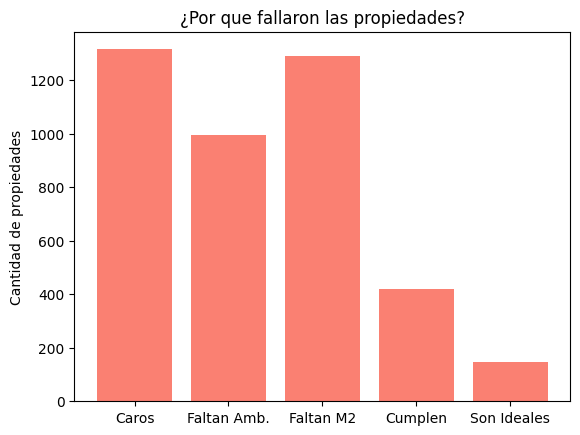


Numero exacto de propiedades por regla:
- Caros: 1316
- Ambientes insuficientes: 997
- Superficie insuficiente: 1292
- Cumplen requisitos: 419
- Muy compatibles: 145

Resumen general:
Cumplen: 419
No cumplen: 2417




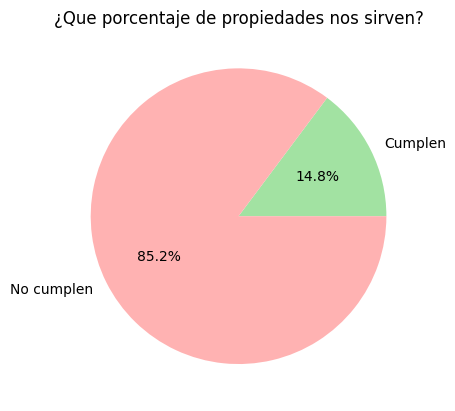

In [16]:
# Contamos cuantas propiedades activaron cada regla.
total_caros = resultados_df["fuera_presupuesto"].sum()
total_amb_chicos = resultados_df["ambientes_insuficientes"].sum()
total_m2_chicos = resultados_df["superficie_insuficiente"].sum()
total_cumplen = resultados_df["cumple_requisitos"].sum()
total_ideales = resultados_df["muy_compatible"].sum()

# GRAFICO 1
nombres_barras = ["Caros", "Faltan Amb.", "Faltan M2", "Cumplen", "Son Ideales"]
alturas_barras = [total_caros, total_amb_chicos, total_m2_chicos, total_cumplen, total_ideales]

# Usamos plt.bar le pasamos nuestras dos listas
plt.bar(nombres_barras, alturas_barras, color="salmon")
plt.title("¿Por que fallaron las propiedades?")
plt.ylabel("Cantidad de propiedades")
plt.show()

print("\nNumero exacto de propiedades por regla:")
print(f"- Caros: {total_caros}")
print(f"- Ambientes insuficientes: {total_amb_chicos}")
print(f"- Superficie insuficiente: {total_m2_chicos}")
print(f"- Cumplen requisitos: {total_cumplen}")
print(f"- Muy compatibles: {total_ideales}")


# Contamos cuantas propiedades cumplen los requisitos.
cumplen = resultados_df["cumple_requisitos"].sum()
# Calculamos cuantas no cumplen.
no_cumplen = len(resultados_df) - cumplen

print("\nResumen general:")
print("Cumplen:", cumplen)
print("No cumplen:", no_cumplen)
print("\n")

# GRAFICO 2
# Calculamos los que no sirven restando el total de filas menos los que sí cumplen
total_filas = len(resultados_df)
total_no_cumplen = total_filas - total_cumplen

pedazos_torta = [total_cumplen, total_no_cumplen]
etiquetas_torta = ["Cumplen", "No cumplen"]

# Hacemos el grafico
plt.pie(pedazos_torta, labels=etiquetas_torta, autopct="%1.1f%%", colors=["#a2e2a2", "#ffb2b2"])
plt.title("¿Que porcentaje de propiedades nos sirven?")
plt.show()

Interpretación del gráfico circular
El gráfico muestra que el 14,8 % de las propiedades analizadas cumple con los requisitos principales definidos por el comprador.

En cambio, el 85,2 % no cumple con al menos una de las condiciones establecidas, como presupuesto máximo, cantidad mínima de ambientes o superficie mínima.

Esto demuestra que el sistema experto funciona como un filtro que permite reducir la cantidad de propiedades a revisar y concentrarse únicamente en aquellas que se ajustan mejor a las necesidades del comprador.

Interpretación del gráfico de barras
De las propiedades analizadas, 1316 se encuentran fuera del presupuesto definido para el comprador.

Además, 997 propiedades tienen una cantidad de ambientes inferior a la solicitada y 1292 presentan una superficie menor a la superficie mínima requerida.

Por otro lado, 419 propiedades cumplen con los requisitos principales de precio, ambientes y superficie.

Dentro de ese grupo, 145 propiedades además coinciden con el tipo de inmueble preferido por el comprador, por lo que el sistema las considera muy compatibles con la búsqueda.

Es importante aclarar que una misma propiedad puede activar más de una regla. Por ejemplo, una propiedad puede estar fuera de presupuesto y al mismo tiempo tener superficie insuficiente.

5️⃣ Evaluación de Métodos
Comparar las técnicas utilizadas (frames, redes, reglas).
Explicar cuál resultó más efectiva y por qué.
(Escribir aquí la comparación y conclusiones)

Evaluación de los métodos utilizados
En este trabajo utilizamos tres formas de representación del conocimiento: frames, redes semánticas y reglas SI–ENTONCES.

Los frames nos permitieron representar una propiedad como una estructura con atributos, por ejemplo tipo de inmueble, precio, superficie, cantidad de ambientes y ubicación.

Las redes semánticas nos permitieron representar las relaciones entre los principales conceptos del sistema, por ejemplo que un comprador tiene un presupuesto y busca una propiedad.

Las reglas SI–ENTONCES fueron fundamentales para que el sistema experto pudiera tomar decisiones. A partir de los datos de la propiedad y de las necesidades del comprador, las reglas permitieron obtener conclusiones como "fuera de presupuesto", "ambientes insuficientes" o "propiedad muy compatible".

De los métodos utilizados, las reglas SI–ENTONCES resultaron especialmente útiles para la toma de decisiones, mientras que los frames y las redes semánticas ayudaron a organizar y representar el conocimiento del sistema.

Por este motivo, consideramos que la combinación de los tres métodos permitió construir un sistema más claro y comprensible.

6️⃣ Conclusión Final del Grupo
Resumir los principales aprendizajes del trabajo.
Indicar posibles mejoras o ampliaciones futuras.
(Conclusión grupal)

Conclusión final del grupo
A través de este trabajo pudimos comprender cómo funciona un sistema experto basado en reglas y cómo puede aplicarse a un problema concreto relacionado con la búsqueda de una primera vivienda.

Utilizamos frames para representar las características de una propiedad, redes semánticas para mostrar las relaciones entre los principales conceptos del sistema y reglas SI–ENTONCES para obtener conclusiones a partir de los datos.

También implementamos un motor de inferencia hacia adelante, que permitió evaluar las propiedades según el presupuesto, la cantidad de ambientes, la superficie y el tipo de inmueble solicitado por el comprador.

El sistema fue conectado con el dataset Buenos Aires Real Estate. De las 8.606 propiedades originales, se seleccionaron 2.836 que contaban con los datos necesarios de precio, superficie y cantidad de ambientes para poder ser evaluadas.

Al aplicar las reglas, el sistema permitió identificar propiedades fuera de presupuesto, con ambientes o superficie insuficientes, así como propiedades que cumplen con los requisitos definidos por el comprador.

Los resultados también fueron representados mediante gráficos para facilitar su interpretación.

Como posibles mejoras futuras, se podría incorporar la ubicación como un criterio adicional de búsqueda, permitir que el usuario ingrese sus propios requisitos y ampliar las reglas para generar recomendaciones más personalizadas.



---



---


##  Fase 3: Metodología Machine Learning
Una vez limpios los datos y filtrados por el Sistema Experto, aplicamos algoritmos de Machine Learning para encontrar patrones complejos y realizar predicciones.

En esta fase utilizaremos:
1. **Regresión Lineal:** Para predecir el precio del inmueble en base a sus características (superficie y ambientes).
2. **Árboles de Decisión (Decision Tree):** Para evaluar la importancia de cada variable en la fijación del precio.
3. **Clustering (K-Means):** Para realizar una segmentación no supervisada del mercado inmobiliario.

In [17]:
print(f"Dimensiones del dataset de trabajo (df_ml): {df_ml.shape}")
df_ml.head(3)

Dimensiones del dataset de trabajo (df_ml): (8606, 16)


,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500,1.636.363.636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2.136.752.137,2.083.333.333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000,1.863.636.364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...


### 1.1 Aplicamos las decisiones de limpieza que tomamos en el EDA
Retomamos lo que ya habíamos acordado como grupo, para que los modelos no aprendan de datos erróneos:
- **Tipos de datos:** Pasamos a formato numérico las columnas que venían como texto (`expenses`, etc.). Los valores con formato roto quedan como `NaN`.
- **Valores en cero o negativos** en precio y superficies: Se eliminan por considerarse errores de carga. Los `NaN` se conservan para no perder registros.
- **Pisos mayores a 60:** Se eliminan por ser errores de tipeo lógicos.
- **`price_usd_per_m2` y `price_per_m2`:** Se recalculan a partir del precio y la superficie.

In [18]:
filas_inicio = len(df_ml)

# 1) Tipos de datos: todo lo numérico a número (lo que no se pueda convertir pasa a NaN)
cols_numericas = ['price', 'price_aprox_local_currency', 'price_aprox_usd',
                  'surface_total_in_m2', 'surface_covered_in_m2',
                  'rooms', 'floor', 'expenses']
for col in cols_numericas:
    df_ml[col] = pd.to_numeric(df_ml[col], errors='coerce')

# 2) Eliminar ceros y negativos en precio y superficies (los NaN se conservan porque NaN <= 0 es False)
for col in ['price', 'price_aprox_usd', 'surface_total_in_m2', 'surface_covered_in_m2']:
    df_ml = df_ml[~(df_ml[col] <= 0)]

# 3) Eliminar pisos imposibles (más de 60)
df_ml = df_ml[~(df_ml['floor'] > 60)]

# 4) Recalcular los precios por m2
df_ml['price_usd_per_m2'] = df_ml['price_aprox_usd'] / df_ml['surface_total_in_m2']
df_ml['price_per_m2'] = df_ml['price'] / df_ml['surface_covered_in_m2']

df_ml = df_ml.reset_index(drop=True)
print(f"Filas antes: {filas_inicio} | Filas después de limpiar: {len(df_ml)} | Eliminadas: {filas_inicio - len(df_ml)}")

Filas antes: 8606 | Filas después de limpiar: 7924 | Eliminadas: 682


## 2. Transformación de variables categóricas – Integrante 2

Antes de entrenar el modelo hay que pasar las variables categóricas (texto) a números. Usamos dos estrategias según la cantidad de categorías: **One-Hot Encoding** para `property_type` y **Binary Encoding** para `place_name`, que tiene muchos valores distintos.

**¿Por qué?** One-Hot crea una columna por cada tipo de propiedad. Binary representa las categorías con pocas columnas binarias y evita crear una columna inmanejable por cada barrio.

La transformación se hace sobre una copia de `df_ml` para conservar el dataset original.

In [19]:
# Librerías para transformar variables categóricas
!pip -q install category_encoders

from sklearn.preprocessing import OneHotEncoder
import category_encoders as ce

# Copiamos el dataset de trabajo
df_ml_codificado = df_ml.copy()

# El dataset NO trae una columna 'place_name': trae 'place_with_parent_names' (ej: |Argentina|Capital Federal|Villa Crespo|).
# Creamos 'place_name' tomando el último nivel no vacío (barrio/localidad).
def extraer_lugar(texto):
    if pd.isna(texto):
        return np.nan
    partes = [p for p in str(texto).split('|') if p.strip() != '']
    return partes[-1].strip() if partes else np.nan

df_ml_codificado['place_name'] = df_ml_codificado['place_with_parent_names'].apply(extraer_lugar)

# Reemplazamos valores faltantes de las variables categóricas por una categoría explícita
df_ml_codificado['property_type'] = df_ml_codificado['property_type'].fillna('desconocido')
df_ml_codificado['place_name'] = df_ml_codificado['place_name'].fillna('desconocido')

print('Categorías de property_type:', df_ml_codificado['property_type'].nunique())
print('Categorías de place_name:', df_ml_codificado['place_name'].nunique())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 5.0 MB/s eta 0:00:00
Categorías de property_type: 4
Categorías de place_name: 336


### One-Hot Encoding: `property_type`
`property_type` es una variable categórica **nominal**. No queremos asignarle números como 1, 2 o 3, porque el modelo podría interpretar un orden que no existe. Por eso usamos One-Hot Encoding.

In [20]:
# One-Hot Encoding para el tipo de propiedad
encoder_ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
tipo_codificado = encoder_ohe.fit_transform(df_ml_codificado[['property_type']])

nombres_ohe = encoder_ohe.get_feature_names_out(['property_type'])
tipo_codificado = pd.DataFrame(tipo_codificado, columns=nombres_ohe, index=df_ml_codificado.index)

# Eliminamos la columna original y agregamos las columnas binarias creadas
df_ml_codificado = pd.concat([df_ml_codificado.drop(columns=['property_type']), tipo_codificado], axis=1)

print('Columnas creadas por One-Hot:')
print(list(nombres_ohe))

Columnas creadas por One-Hot:
['property_type_PH', 'property_type_apartment', 'property_type_house', 'property_type_store']


### Binary Encoding: `place_name`
`place_name` tiene muchas categorías (barrios/localidades). Aplicar One-Hot directamente generaría una columna por barrio. Con **Binary Encoding** cada categoría se representa con un código binario repartido en pocas columnas.

In [21]:
# Binary Encoding para la ubicación
encoder_bin = ce.BinaryEncoder(cols=['place_name'])
df_ml_codificado = encoder_bin.fit_transform(df_ml_codificado)

print('Dimensiones antes de la codificación:', df_ml.shape)
print('Dimensiones después de la codificación:', df_ml_codificado.shape)
display(df_ml_codificado.head())

Dimensiones antes de la codificación: (7924, 16)
Dimensiones después de la codificación: (7924, 28)


,operation,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,...,place_name_3,place_name_4,place_name_5,place_name_6,place_name_7,place_name_8,property_type_PH,property_type_apartment,property_type_house,property_type_store
0,sell,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,...,0,0,0,0,0,1,0.0,1.0,0.0,0.0
1,sell,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2136.752137,...,0,0,0,0,1,0,0.0,0.0,1.0,0.0
2,sell,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000.000000,...,0,0,0,0,1,1,0.0,0.0,1.0,0.0
3,sell,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900.000000,...,0,0,0,1,0,0,0.0,0.0,1.0,0.0
4,sell,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,...,0,0,0,1,0,1,0.0,1.0,0.0,0.0


### Resultado de la transformación
`df_ml_codificado` tiene ahora las variables categóricas en formato numérico y queda listo para que se definan `X` e `y`.

**Importante:** no se codifica `price` porque es lo que queremos predecir. Tampoco usamos como predictoras las variables que se calculan a partir del precio, para no darle al modelo información del objetivo.

In [22]:
# Dejamos la versión codificada como dataset de trabajo para las etapas siguientes
df_ml = df_ml_codificado.copy()
print('df_ml quedó actualizado con las variables categóricas codificadas.')

df_ml quedó actualizado con las variables categóricas codificadas.


### 2. Modelo de Machine Learning: Regresión Lineal

Para dar cumplimiento al objetivo de estimar el precio de las propiedades en dólares, se implementará un modelo de aprendizaje supervisado de **Regresión**.

El proceso metodológico consta de las siguientes etapas:
1. **Selección de características (*Features* y *Target*):** Se seleccionan variables numéricas clave (como la superficie total y la cantidad de ambientes) que poseen una correlación directa con el valor del inmueble.
2. **Partición de los datos:** Se divide el conjunto de datos en subconjuntos de entrenamiento y prueba para evitar el sobreajuste (*overfitting*).
3. **Entrenamiento y Evaluación:** Se entrena un modelo de Regresión Lineal como estimador base y se evalúa su rendimiento mediante métricas estándar (\(R^2\) y Error Cuadrático Medio).

In [23]:
features = ['surface_total_in_m2', 'rooms']
df_reg = df_ml.dropna(subset=features + ['price']).copy()

X = df_reg[features]
y = df_reg['price']

# Dividimos el dataset (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Entrenamos el modelo
modelo_reg = LinearRegression()
modelo_reg.fit(X_train, y_train)

print("¡Modelo entrenado con éxito!")

¡Modelo entrenado con éxito!


### 📉 Evaluación del Modelo de Regresión
Evaluamos el rendimiento del modelo utilizando el conjunto de prueba (`X_test`). Calculamos dos métricas clave:
1. **$R^2$ (Coeficiente de Determinación):** Indica qué porcentaje de la variabilidad del precio explican nuestras variables (lo ideal es que se acerque a 1).
2. **MSE (Error Cuadrático Medio):** Mide la magnitud promedio de los errores de predicción al cuadrado.

In [24]:
y_pred = modelo_reg.predict(X_test)
print(f"R^2 Score (Coeficiente de Determinación): {r2_score(y_test, y_pred):.4f}")
print(f"Error Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.2f}")

R^2 Score (Coeficiente de Determinación): -0.3611
Error Cuadrático Medio (MSE): 167697890564.92


**Análisis e Interpretación de Resultados:**
R² Score: El valor obtenido evidencia que el modelo lineal simple, basado únicamente en dos variables (surface_total_in_m2 y rooms), presenta limitaciones para explicar por completo la variabilidad de los precios inmobiliarios en Buenos Aires. Esto demuestra la necesidad de incorporar variables categóricas clave (como la ubicación o el barrio) y aplicar transformaciones o modelos más avanzados.

Error Cuadrático Medio (MSE): Al encontrarse en unidades monetarias al cuadrado, refleja la dispersión de los errores de estimación, sirviendo como línea de base para futuras optimizaciones del modelo.

Estos resultados son fundamentales metodológicamente, ya que justifican la necesidad de implementar ingeniería de características y codificación de variables categóricas (encoders) en las siguientes etapas del proyecto.

## 💡 3) Desarrollo de Modelos Avanzados: Árbol de Decisión
Buscamos capturar relaciones no lineales que la regresión simple no pudo detectar, implementando un `DecisionTreeRegressor`.

R^2 Score (Árbol): -0.3476


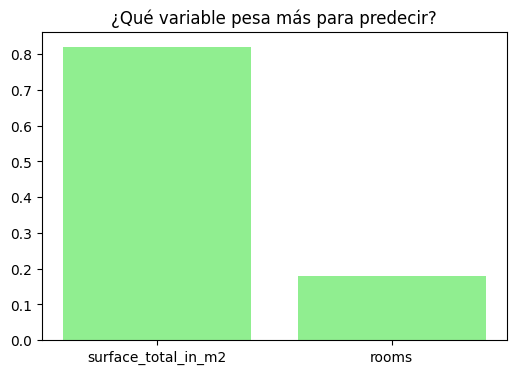

In [25]:
# 1. Entrenar y predecir
modelo_arbol = DecisionTreeRegressor(max_depth=5, random_state=42)
modelo_arbol.fit(X_train, y_train)
y_pred_arbol = modelo_arbol.predict(X_test)

print(f"R^2 Score (Árbol): {r2_score(y_test, y_pred_arbol):.4f}")

# 2. Gráfico de importancia (Transparencia)
plt.figure(figsize=(6,4))
plt.bar(features, modelo_arbol.feature_importances_, color="lightgreen")
plt.title("¿Qué variable pesa más para predecir?")
plt.show()

### 📊 Análisis e Interpretación de Resultados (Árbol de Decisión):
- **Desempeño del Modelo:** Aunque el R² pueda mostrar ligeras variaciones, sigue evidenciando que predecir el precio basándose solo en dos variables físicas es insuficiente, reforzando la hipótesis de incorporar datos espaciales.
- **Transparencia y Explicabilidad:** El gráfico generado revela la "importancia de las variables", mostrando matemáticamente cómo el modelo toma sus decisiones. Mide de 0 a 1 el porcentaje que toma el Árbol para evaluar propiedades según los metros cuadrados frente a los ambientes. Esto es vital para asegurar que nuestro sistema no sea una "caja negra" y sus resultados sean interpretables.

---
## 🧩 4) Desarrollo del Modelo de Clasificación (Clustering)
A diferencia de los modelos predictivos, aquí aplicaremos un enfoque de Aprendizaje No Supervisado utilizando **K-Means**.

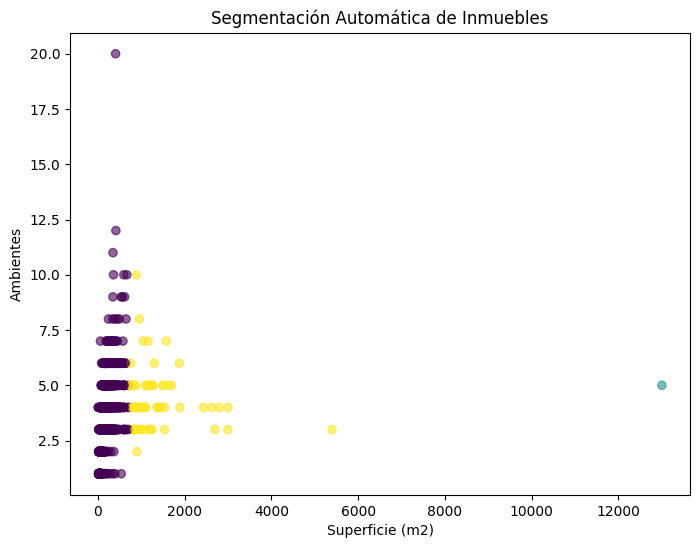

In [26]:
# 1. Crear 3 grupos automáticos
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
df_reg['segmento'] = kmeans.fit_predict(X)

# 2. Gráfico de los grupos
plt.figure(figsize=(8,6))
plt.scatter(df_reg['surface_total_in_m2'], df_reg['rooms'], c=df_reg['segmento'], cmap='viridis', alpha=0.6)
plt.xlabel("Superficie (m2)")
plt.ylabel("Ambientes")
plt.title("Segmentación Automática de Inmuebles")
plt.show()

### 📊 Análisis e Interpretación del Gráfico (K-Means):
El algoritmo logró segmentar los inmuebles en 3 clústeres basándose únicamente en sus características físicas, trabajando de forma autónoma sin conocer el precio.

- **Punto Verde / Aislado:** Inmuebles anormales o atípicos de superficies irreales para la cantidad de ambientes (posible error de carga residual).
- **Puntos Amarillos:** Propiedades de gran tamaño (entre 500 m² y 4000 m²), correspondientes a terrenos o grandes edificaciones.
- **Puntos Violetas:** Propiedades habitacionales normales para vivienda tradicional (menos de 500 m²).

**Justificación Metodológica:** Esta técnica nos permite descubrir la estructura oculta de los datos y perfilar segmentos naturales del mercado. En futuras iteraciones, esto servirá para entrenar modelos predictivos específicos para cada segmento (ej. un modelo solo para viviendas tradicionales), reduciendo el error drásticamente.

Documentación Interna
Verificar que cada celda de código tenga comentarios claros.
Mantener un hilo conductor: Introducción → Desarrollo → Resultados → Conclusiones.

# 🧠 Redes Neuronales – Parte 1: Preparación y Preprocesamiento de Datos

**Objetivo:** dejar los datos listos para que el Integrante 2 construya el Perceptrón Multicapa (FNN) y el Integrante 3 lo entrene.

**Variable a predecir (target):** `price_aprox_usd` (precio aproximado en dólares).

Pasos de esta sección:
1. Partir del dataset original (`inmuebles`) y aplicar las decisiones de limpieza que el grupo ya tomó en el EDA.
2. Revisar la estructura final de los datos limpios.
3. Separar `X` (variables predictoras) e `y` (target).
4. Hacer el `train_test_split`.
5. Codificar las variables categóricas (One-Hot Encoding) y normalizar las numéricas (StandardScaler).

> **Orden importante:** primero se hace el `train_test_split` y *después* se ajustan (`fit`) el encoder y el scaler **solo con el set de entrenamiento**. Si se ajustaran con todos los datos, el modelo "vería" información del test antes de tiempo (*data leakage*) y las métricas saldrían más optimistas de lo real.

In [27]:
# Librerías para el preprocesamiento
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
# Semilla fija: así todo el grupo obtiene exactamente la misma partición
SEED = 42

# Reutilizamos df_ml, que ya tiene aplicada la limpieza del EDA

In [28]:
# Partimos de df_ml: ya tiene la limpieza del EDA aplicada (ceros, pisos > 60, tipos numéricos)
df_nn = df_ml.copy()
filas_inicio = len(df_nn)

# 1) Recuperamos 'property_type' desde las columnas One-Hot que ya existen
#    (ej: property_type_apartment = 1  ->  'apartment')
cols_tipo = [c for c in df_nn.columns if c.startswith('property_type_')]
df_nn['property_type'] = df_nn[cols_tipo].idxmax(axis=1).str.replace('property_type_', '')

# 2) Variables de ubicación a partir de 'place_with_parent_names'
def extraer_nivel(texto, nivel):
    partes = [p.strip() for p in str(texto).split('|') if p.strip() != '']
    if nivel == 'zona':
        return partes[1] if len(partes) > 1 else 'desconocido'
    return partes[-1] if partes else 'desconocido'

df_nn['zona'] = df_nn['place_with_parent_names'].apply(lambda t: extraer_nivel(t, 'zona'))
df_nn['barrio'] = df_nn['place_with_parent_names'].apply(lambda t: extraer_nivel(t, 'barrio'))

# 3) Nos quedamos con las columnas del modelo y sin faltantes
columnas_modelo = ['property_type', 'zona', 'barrio', 'surface_total_in_m2', 'rooms', 'price_aprox_usd']
df_nn = df_nn[columnas_modelo].dropna().reset_index(drop=True)

print(f"Filas de df_ml: {filas_inicio} | Filas listas para la red neuronal: {len(df_nn)}")

Filas de df_ml: 7924 | Filas listas para la red neuronal: 2556


## 2. Revisión de la estructura final de los datos limpios
Antes de seguir, verificamos tipos, nulos, estadísticas y valores extremos.

Dimensiones (filas, columnas): (2556, 6)

Tipos de datos:
property_type           object
zona                    object
barrio                  object
surface_total_in_m2    float64
rooms                  float64
price_aprox_usd        float64
dtype: object

Nulos por columna:
property_type          0
zona                   0
barrio                 0
surface_total_in_m2    0
rooms                  0
price_aprox_usd        0
dtype: int64

Estadísticas de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max
surface_total_in_m2,2556.0,164.165884,358.966070,10.00,51.0,81.0,175.25,13000.0
rooms,2556.0,3.072770,1.433792,1.00,2.0,3.0,4.00,20.0
price_aprox_usd,2556.0,214416.062437,250942.412115,10523.13,90000.0,140000.0,249600.00,3900000.0



Categorías de property_type:
property_type
apartment    1609
house         716
PH            212
store          19
Name: count, dtype: int64

Categorías de zona:
zona
Capital Federal             1099
Bs.As. G.B.A. Zona Norte     648
Bs.As. G.B.A. Zona Oeste     619
Bs.As. G.B.A. Zona Sur       190
Name: count, dtype: int64

Cantidad de barrios distintos: 207


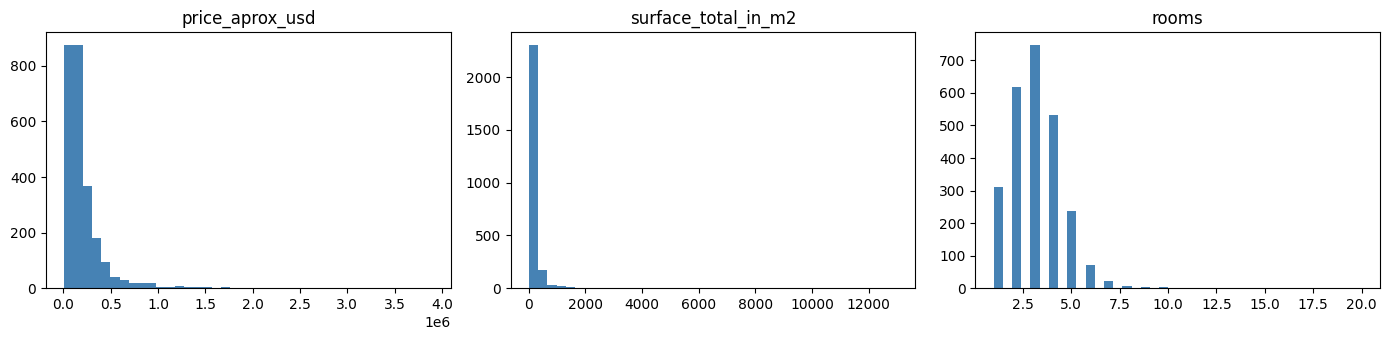

In [29]:
print("Dimensiones (filas, columnas):", df_nn.shape)
print("\nTipos de datos:")
print(df_nn.dtypes)
print("\nNulos por columna:")
print(df_nn.isnull().sum())

print("\nEstadísticas de las variables numéricas:")
display(df_nn[['surface_total_in_m2', 'rooms', 'price_aprox_usd']].describe().T)

print("\nCategorías de property_type:")
print(df_nn['property_type'].value_counts())
print("\nCategorías de zona:")
print(df_nn['zona'].value_counts())
print("\nCantidad de barrios distintos:", df_nn['barrio'].nunique())

# Distribución de las variables numéricas (para detectar valores extremos)
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.5))
for eje, col in zip(ejes, ['price_aprox_usd', 'surface_total_in_m2', 'rooms']):
    eje.hist(df_nn[col], bins=40, color='steelblue')
    eje.set_title(col)
plt.tight_layout()
plt.show()

### Valores extremos (outliers)
En el EDA vimos superficies de hasta 62.034 m² y precios de varios millones de dólares. Con `StandardScaler`, unos pocos valores gigantes "aplastan" al resto de los datos y la red aprende peor.

Dejamos un interruptor (`FILTRAR_OUTLIERS`) que recorta el 1 % superior de precio y superficie.

In [30]:
FILTRAR_OUTLIERS = True

if FILTRAR_OUTLIERS:
    tope_precio = df_nn['price_aprox_usd'].quantile(0.99)
    tope_sup = df_nn['surface_total_in_m2'].quantile(0.99)
    antes = len(df_nn)
    df_nn = df_nn[(df_nn['price_aprox_usd'] <= tope_precio) &
                  (df_nn['surface_total_in_m2'] <= tope_sup)].reset_index(drop=True)
    print(f"Tope de precio: USD {tope_precio:,.0f} | Tope de superficie: {tope_sup:,.0f} m²")
    print(f"Filas antes: {antes} | después: {len(df_nn)} | eliminadas: {antes - len(df_nn)}")
else:
    print("No se filtraron outliers. Filas:", len(df_nn))

Tope de precio: USD 1,250,000 | Tope de superficie: 1,222 m²
Filas antes: 2556 | después: 2508 | eliminadas: 48


## 3. Definición de X e y
- **Target (`y`):** `price_aprox_usd`. Usamos el precio *en dólares* y no `price`, porque `price` mezcla propiedades publicadas en dólares y en pesos (`currency` = USD / ARS) y no son comparables.
- **Variables numéricas:** `surface_total_in_m2`, `rooms`.
- **Variables categóricas:** `property_type`, `zona`, `barrio`.
- **No usamos** `price`, `price_aprox_local_currency`, `price_usd_per_m2` ni `price_per_m2` como predictoras: se calculan a partir del precio, así que le "regalarían" la respuesta al modelo. Tampoco `floor` y `expenses` (más del 85 % de faltantes).

In [31]:
cols_num = ['surface_total_in_m2', 'rooms']
cols_cat = ['property_type', 'zona', 'barrio']

X = df_nn[cols_num + cols_cat]
y = df_nn['price_aprox_usd']

print("X:", X.shape, "| y:", y.shape)
display(X.head())

X: (2508, 5) | y: (2508,)


,surface_total_in_m2,rooms,property_type,zona,barrio
0,120.0,4.0,apartment,Capital Federal,Villa Crespo
1,117.0,4.0,house,Bs.As. G.B.A. Zona Oeste,Ramos Mejía
2,200.0,5.0,house,Bs.As. G.B.A. Zona Oeste,Tres de Febrero
3,61.0,2.0,apartment,Bs.As. G.B.A. Zona Norte,Nordelta
4,150.0,3.0,PH,Bs.As. G.B.A. Zona Oeste,Haedo


## 4. Train / Test split
80 % para entrenar y 20 % para evaluar. El set de test no se toca hasta la evaluación final. (El set de **validación** para las curvas de aprendizaje lo toma Keras desde el entrenamiento con `validation_split` en `model.fit`.)

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)

Entrenamiento: (2006, 5) | Test: (502, 5)


## 5. One-Hot Encoding + StandardScaler
Con un `ColumnTransformer` aplicamos a cada grupo de columnas su transformación:
- **Categóricas → One-Hot Encoding.** Cada categoría pasa a ser una columna 0/1. Se usa One-Hot (y no 1, 2, 3...) porque estas variables son *nominales*: no tienen un orden, y un número le haría creer a la red que sí.
  - `min_frequency=30` agrupa los barrios con menos de 30 propiedades en una categoría "poco frecuente", así no se crean cientos de columnas casi vacías.
  - `handle_unknown='infrequent_if_exist'` evita errores si en el test aparece un barrio que no estaba en el entrenamiento.
- **Numéricas → StandardScaler.** Deja cada variable con media 0 y desvío 1, para que los metros cuadrados (cientos) no pesen más que los ambientes (1 a 10) solo por tener una escala mayor.

El `fit` se hace **solo con `X_train`**; al test solo se le aplica `transform`.

In [33]:
preprocesador = ColumnTransformer(transformers=[
    ('num', StandardScaler(), cols_num),
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist',
                          min_frequency=30,
                          sparse_output=False), cols_cat)
])

# fit SOLO con entrenamiento; transform en ambos
X_train_proc = preprocesador.fit_transform(X_train).astype('float32')
X_test_proc = preprocesador.transform(X_test).astype('float32')

nombres_columnas = preprocesador.get_feature_names_out()
print("X_train procesado:", X_train_proc.shape)
print("X_test procesado: ", X_test_proc.shape)
print("Cantidad de columnas (entradas de la red):", X_train_proc.shape[1])
print("\nPrimeras columnas:", list(nombres_columnas[:8]))

# Verificación: las numéricas del train deben tener media ~0 y desvío ~1
print("\nMedia de las numéricas (train):", X_train_proc[:, :len(cols_num)].mean(axis=0).round(3))
print("Desvío de las numéricas (train):", X_train_proc[:, :len(cols_num)].std(axis=0).round(3))
print("¿Hay NaN?:", np.isnan(X_train_proc).any() or np.isnan(X_test_proc).any())

X_train procesado: (2006, 28)
X_test procesado:  (502, 28)
Cantidad de columnas (entradas de la red): 28

Primeras columnas: ['num__surface_total_in_m2', 'num__rooms', 'cat__property_type_PH', 'cat__property_type_apartment', 'cat__property_type_house', 'cat__property_type_infrequent_sklearn', 'cat__zona_Bs.As. G.B.A. Zona Norte', 'cat__zona_Bs.As. G.B.A. Zona Oeste']

Media de las numéricas (train): [0. 0.]
Desvío de las numéricas (train): [1. 1.]
¿Hay NaN?: False


### Normalización del target
El precio llega a cientos de miles de dólares y, con MSE, los errores al cuadrado serían números enormes que dificultan el entrenamiento. Por eso también estandarizamos `y`. **Para interpretar resultados hay que "des-estandarizar" las predicciones** con `scaler_y.inverse_transform(...)` (necesario para el gráfico de predicciones vs. valores reales y para informar el error en dólares).

In [34]:
scaler_y = StandardScaler()
y_train_esc = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel().astype('float32')
y_test_esc = scaler_y.transform(y_test.values.reshape(-1, 1)).ravel().astype('float32')

print("y_train escalado -> media:", y_train_esc.mean().round(3), "| desvío:", y_train_esc.std().round(3))
print("Ejemplo: precio real", y_train.iloc[0], "-> escalado", y_train_esc[0].round(3))

y_train escalado -> media: 0.0 | desvío: 1.0
Ejemplo: precio real 92000.0 -> escalado -0.608


## 🧠 Redes Neuronales - Parte 2: Diseño de la Arquitectura del Modelo-Perez Fernanda

En esta parte se construye la arquitectura de la red neuronal que vamos a usar para predecir el precio aproximado en dólares de una propiedad.

El modelo elegido es una **FNN o Perceptrón Multicapa**, porque nuestro dataset tiene datos tabulares, es decir, datos organizados en filas y columnas.

La red recibe como entrada las variables ya preparadas en la Parte 1, como superficie, ambientes, tipo de propiedad, zona y barrio. Luego, mediante capas densas, intenta aprender la relación entre esas características y el precio.

En esta sección solo se arma y compila el modelo. El entrenamiento lo realizará el siguiente integrante.

In [35]:
# Librerías para crear la red neuronal
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [36]:
# Parte 2 - Diseño del modelo de red neuronal
# En esta parte armamos la estructura del modelo.
# Los datos ya vienen preparados de la parte anterior.

modelo = keras.Sequential([
    # Capa de entrada: recibe la cantidad de columnas que quedaron después del preprocesamiento
    layers.Input(shape=(X_train_proc.shape[1],)),

    # Primera capa oculta con 64 neuronas
    layers.Dense(64, activation='relu'),

    # Segunda capa oculta con 32 neuronas
    layers.Dense(32, activation='relu'),

    # Capa de salida con 1 neurona porque queremos predecir un precio
    layers.Dense(1)
])

# Compilamos el modelo para que después pueda entrenarse
modelo.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Mostramos un resumen del modelo armado
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,969 (15.50 KB)

 Trainable params: 3,969 (15.50 KB)

 Non-trainable params: 0 (0.00 B)

##📊 Gráfico 1: Curvas de Aprendizaje (Pérdida de Entrenamiento vs. Validación)
¿Qué estamos viendo acá?
Es el gráfico que nos muestra la salud del entrenamiento de la red neuronal paso a paso. En el eje horizontal tenemos las épocas (las veces que la red pasó por todo el dataset aprendiendo) y en el vertical el error o pérdida (loss).

Línea de entrenamiento (Loss): Mide cuánto se equivoca la red con los datos con los que está entrenando. Tiene que bajar constantemente.

Línea de validación (Val Loss): Mide cuánto se equivoca con datos que la red nunca vio antes.

Si ambas líneas bajan juntas y se aplanan, significa que el modelo aprendió a generalizar bien y no se memorizó los datos de memoria (no hay overfitting).

Epoch 1/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 0.6421 - mae: 0.5050 - val_loss: 0.4853 - val_mae: 0.3863
Epoch 2/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.4859 - mae: 0.4034 - val_loss: 0.4232 - val_mae: 0.3735
Epoch 3/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4349 - mae: 0.3818 - val_loss: 0.3964 - val_mae: 0.3733
Epoch 4/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.4023 - mae: 0.3661 - val_loss: 0.3766 - val_mae: 0.3600
Epoch 5/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3821 - mae: 0.3524 - val_loss: 0.3652 - val_mae: 0.3527
Epoch 6/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3604 - mae: 0.3469 - val_loss: 0.3495 - val_mae: 0.3366
Epoch 7/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3592 - mae: 0.3462 - val_loss: 0.3431 - val_mae: 0.3283
Epoch 8/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.3487 - mae: 0.3401 - val_loss: 0.3603 - val_mae: 0.3621
Epoch 9/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.3495

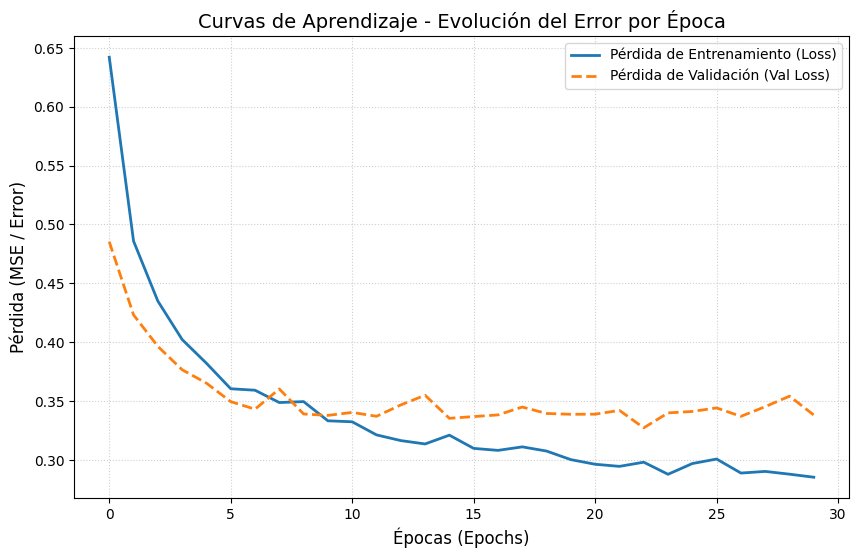

In [37]:
# 1. Entrenamos el modelo guardando el historial en la variable 'history'
history = modelo.fit(
    X_train_proc, y_train_esc,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    verbose=1
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Graficamos la pérdida de entrenamiento
plt.plot(history.history['loss'], label='Pérdida de Entrenamiento (Loss)', linewidth=2)

# Graficamos la pérdida de validación
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], label='Pérdida de Validación (Val Loss)', linewidth=2, linestyle='--')

plt.title('Curvas de Aprendizaje - Evolución del Error por Época', fontsize=14)
plt.xlabel('Épocas (Epochs)', fontsize=12)
plt.ylabel('Pérdida (MSE / Error)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

El modelo quedó formado por una capa de entrada, dos capas ocultas densas y una capa de salida.

Las capas ocultas tienen 64 y 32 neuronas, y usan la función de activación ReLU. La capa de salida tiene una sola neurona porque buscamos predecir un solo valor: el precio.

El modelo se compiló con el optimizador Adam, la función de pérdida MSE y la métrica MAE.

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


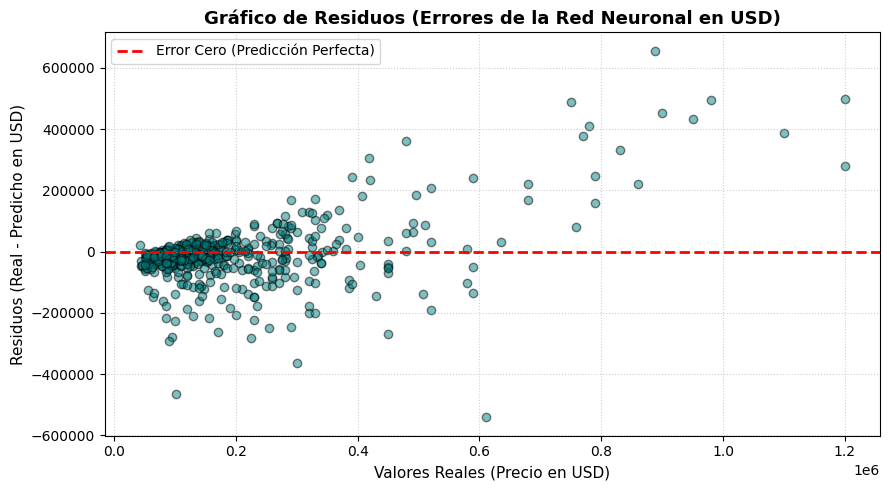

In [38]:
# 1. Obtenemos las predicciones usando los datos preprocesados (X_test_proc)
y_pred_esc = modelo.predict(X_test_proc)

# Des-escalamos las predicciones para volver a la escala original en dólares
y_pred = scaler_y.inverse_transform(y_pred_esc).flatten()
y_test_array = np.array(y_test).flatten()

# 2. Calculamos los residuos en dólares (Valor Real - Valor Predicho)
residuos = y_test_array - y_pred

# 3. Armamos el gráfico de residuos
plt.figure(figsize=(9, 5))
plt.scatter(y_test_array, residuos, alpha=0.5, color='teal', edgecolors='k')

# Línea horizontal de referencia en el error cero
plt.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Error Cero (Predicción Perfecta)')

# Estética y títulos
plt.title('Gráfico de Residuos (Errores de la Red Neuronal en USD)', fontsize=13, fontweight='bold')
plt.xlabel('Valores Reales (Precio en USD)', fontsize=11)
plt.ylabel('Residuos (Real - Predicho en USD)', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=2319643e-25a8-4d42-a202-f6094690deca' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>